# Neighborhood expression

In [1]:
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy import sparse
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
from Xenium_5K_IPF_constants import WORK_PATH, SUBTYPE_HATCHES

radius = 80.0
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl
REV_PATH=f"{WORK_PATH}Revision/106/"
os.makedirs(REV_PATH, exist_ok=True)

In [2]:
adata = sc.read_h5ad(f"{WORK_PATH}Anndata/spatial_merged.h5ad")

In [3]:
cp_df = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv",index_col="cell_id")
meta_data = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv",index_col="cell_id")

In [4]:
adata = adata[meta_data.index,].copy()

In [5]:
adata.obs["subtype"]=meta_data["subtype"].copy()

In [6]:
anchor_ids = adata.obs_names.intersection(cp_df.index)
anchor_obs = adata.obs.loc[anchor_ids, ["sample", "subtype"]].copy()
anchor_obs["continuum_position"] = cp_df.loc[anchor_ids, "C_position"]

In [7]:
n_bins = 20

anchor_obs["continuum_bin"] = pd.cut(
    anchor_obs["continuum_position"],
    bins=np.linspace(0, 1, n_bins + 1),
    labels=False,
    include_lowest=True
)

In [8]:
X = adata.X

## Per-cell neighborhood expression

In [9]:
def build_neighborhood_expression(
    adata,
    anchor_obs,
    sample,
    X,
    radius=80.0
):
    # cells in this sample
    sample_mask = adata.obs["sample"].astype(str).values == sample
    sample_idx = np.where(sample_mask)[0]

    sample_cells = adata.obs_names[sample_idx]
    sample_xy = adata.obsm["spatial"][sample_idx]

    # epithelial anchors in this sample
    sample_anchor_ids = anchor_obs.index[
        anchor_obs["sample"].astype(str) == sample
    ]

    anchor_idx_local = sample_cells.get_indexer(sample_anchor_ids)

    if np.any(anchor_idx_local < 0):
        raise ValueError(f"Anchor mapping failed in {sample}")

    anchor_xy = sample_xy[anchor_idx_local]

    # 80 µm neighborhoods
    tree = cKDTree(sample_xy)
    neighbors = tree.query_ball_point(anchor_xy, r=radius)

    rows = []
    cols = []

    for i, inds in enumerate(neighbors):
        rows.extend([i] * len(inds))
        cols.extend(inds)

    rows = np.asarray(rows, dtype=np.int32)
    cols = np.asarray(cols, dtype=np.int32)

    A = sparse.csr_matrix(
        (
            np.ones(len(rows), dtype=np.float32),
            (rows, cols)
        ),
        shape=(len(sample_anchor_ids), len(sample_cells))
    )

    # raw neighborhood expression
    X_sample = X[sample_idx]
    neigh_expr = A @ X_sample

    # neighborhood cell number
    n_cells = np.asarray(A.sum(axis=1)).ravel()

    # per-neighbor-cell expression
    neigh_expr_per_cell = (
        sparse.diags(1.0 / np.maximum(n_cells, 1))
        @ neigh_expr
    )

    # metadata
    meta = anchor_obs.loc[sample_anchor_ids].copy()

    total_transcripts = np.asarray(
        neigh_expr.sum(axis=1)
    ).ravel()

    meta["n_cells"] = n_cells
    meta["total_transcripts"] = total_transcripts
    meta["transcripts_per_cell"] = (
        total_transcripts / np.maximum(n_cells, 1)
    )

    return {
        "A": A,
        "anchor_ids": sample_anchor_ids,
        "neigh_expr": neigh_expr,
        "neigh_expr_per_cell": neigh_expr_per_cell,
        "meta": meta
    }

In [10]:
samples = anchor_obs["sample"].astype(str).unique()

neigh_results = {}

for s in samples:
    print("Processing:", s)

    neigh_results[s] = build_neighborhood_expression(
        adata=adata,
        anchor_obs=anchor_obs,
        sample=s,
        X=X,
        radius=80.0
    )

Processing: AF_s2
Processing: FR_s1
Processing: FR_s3
Processing: FR_s4
Processing: HC_s1
Processing: HC_s3


In [11]:
all_bin_info = []
all_bin_expr = []
all_bin_expr_per_cell = []

for s, res in neigh_results.items():

    meta = res["meta"]
    Y = res["neigh_expr"]
    Y_pc = res["neigh_expr_per_cell"]

    bin_ids = meta["continuum_bin"].to_numpy()

    for b in sorted(meta["continuum_bin"].dropna().unique()):

        mask = bin_ids == b

        y_total = np.asarray(
            Y[mask].mean(axis=0)
        ).ravel()

        y_pc = np.asarray(
            Y_pc[mask].mean(axis=0)
        ).ravel()

        all_bin_expr.append(y_total)
        all_bin_expr_per_cell.append(y_pc)

        all_bin_info.append({
            "sample": s,
            "continuum_bin": int(b),
            "n_anchors": int(mask.sum()),
            "mean_continuum_position":
                meta.loc[mask, "continuum_position"].mean(),
            "mean_n_cells":
                meta.loc[mask, "n_cells"].mean(),
            "mean_total_transcripts":
                meta.loc[mask, "total_transcripts"].mean(),
            "mean_transcripts_per_cell":
                meta.loc[mask, "transcripts_per_cell"].mean()
        })

all_bin_info = pd.DataFrame(all_bin_info)

all_bin_expr = np.vstack(all_bin_expr)
all_bin_expr_per_cell = np.vstack(all_bin_expr_per_cell)

In [12]:
gene_detected = (all_bin_expr > 0).sum(axis=0)

keep_genes = gene_detected >= 5

In [13]:
X_total = np.log1p(all_bin_expr[:, keep_genes])
X_pc = np.log1p(all_bin_expr_per_cell[:, keep_genes])

In [14]:
pca_total = PCA(n_components=10)
pcs_total = pca_total.fit_transform(X_total)

pca_pc = PCA(n_components=10)
pcs_pc = pca_pc.fit_transform(X_pc)

In [15]:
pca_df = all_bin_info.copy()
n_pca = 5

for n in range(n_pca):
    pca_df[f"PC{n+1}_total"] = pcs_total[:, n]
    pca_df[f"PC{n+1}_per_cell"] = pcs_pc[:, n]


In [16]:
print("Total expression PCA:", pca_total.explained_variance_ratio_[:n_pca])
print("Per-cell expression PCA:", pca_pc.explained_variance_ratio_[:n_pca])

Total expression PCA: [0.5963121  0.14437558 0.03545304 0.03190051 0.02469626]
Per-cell expression PCA: [0.5177987  0.15455541 0.07754411 0.043488   0.03298276]


In [17]:
cols = [f"PC{n+1}_total" for n in range(n_pca)]+[f"PC{n+1}_per_cell" for n in range(n_pca)]
for col in cols:
    rho, p = spearmanr(pca_df[col], pca_df["mean_continuum_position"])
    print(col, "rho =", round(rho, 3), "p =", p)

PC1_total rho = 0.528 p = 7.776068803169576e-10
PC2_total rho = 0.62 p = 7.161767610006167e-14
PC3_total rho = -0.364 p = 5.0575466582300014e-05
PC4_total rho = 0.041 p = 0.6609835912895115
PC5_total rho = 0.055 p = 0.5567707887315954
PC1_per_cell rho = 0.233 p = 0.011023125442526819
PC2_per_cell rho = -0.9 p = 1.1175392986949598e-43
PC3_per_cell rho = 0.083 p = 0.370208988737455
PC4_per_cell rho = -0.232 p = 0.011299809152642157
PC5_per_cell rho = 0.207 p = 0.024485755573373204


In [18]:
# total
bar_total = pd.DataFrame(0.0, 
                         index=[f"PC{n+1}" for n in range(n_pca)], 
                         columns=["rho", "p", "variance"]
                        )

cols_total = [f"PC{n+1}_total" for n in range(n_pca)]
vrs =  pca_total.explained_variance_ratio_[:n_pca]
for n, (col, vr) in enumerate(zip(cols_total, vrs)):
    rho, p = spearmanr(pca_df[col], pca_df["mean_continuum_position"])
    bar_total.loc[f"PC{n+1}", "rho"] = rho
    bar_total.loc[f"PC{n+1}", "p"] = p
    bar_total.loc[f"PC{n+1}", "variance"] = vr

bar_total["abs_rho"] = bar_total["rho"].abs()


# per cell
bar_pc = pd.DataFrame(0.0, 
                      index=[f"PC{n+1}" for n in range(n_pca)], 
                      columns=["rho", "p", "variance"]
                     )

cols_pc = [f"PC{n+1}_per_cell" for n in range(n_pca)]
vrs =  pca_pc.explained_variance_ratio_[:n_pca]
for n, (col, vr) in enumerate(zip(cols_pc, vrs)):
    rho, p = spearmanr(pca_df[col], pca_df["mean_continuum_position"])
    bar_pc.loc[f"PC{n+1}", "rho"] = rho
    bar_pc.loc[f"PC{n+1}", "p"] = p
    bar_pc.loc[f"PC{n+1}", "variance"] = vr    


bar_pc["abs_rho"] = bar_pc["rho"].abs()


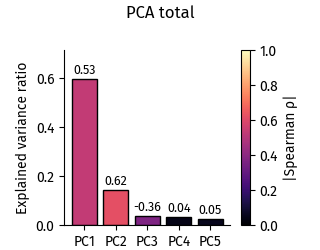

In [19]:
fig, ax = plt.subplots(figsize=(3.2, 2.5))
fig.subplots_adjust(left=0.2, right=0.85, bottom=0.1, top=0.8)

# Color: |Spearman rho|
cmap = plt.colormaps["magma"]
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

bars = ax.bar(x=bar_total.index, height=bar_total["variance"], color=cmap(norm(bar_total["abs_rho"])), ec="black")

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("|Spearman ρ|")

# Spearman rho labels (signed)
for bar, rho in zip(bars, bar_total["rho"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rho:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylabel("Explained variance ratio")
ax.set_ylim(0, bar_total["variance"].max() * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.suptitle("PCA total")
fig.savefig(f"{REV_PATH}barplot_PCA_total.png", dpi=500, format="png", bbox_inches=None)


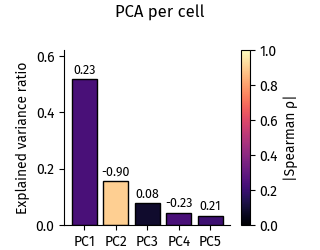

In [20]:
fig, ax = plt.subplots(figsize=(3.2, 2.5))
fig.subplots_adjust(left=0.2, right=0.85, bottom=0.1, top=0.8)

# Color: |Spearman rho|
cmap = plt.colormaps["magma"]
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

bars = ax.bar(x=bar_pc.index, height=bar_pc["variance"], color=cmap(norm(bar_pc["abs_rho"])), ec="black")

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("|Spearman ρ|")

# Spearman rho labels (signed)
for bar, rho in zip(bars, bar_pc["rho"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rho:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylabel("Explained variance ratio")
ax.set_ylim(0, bar_pc["variance"].max() * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.suptitle("PCA per cell")
fig.savefig(f"{REV_PATH}barplot_PCA_percell.png", dpi=500, format="png", bbox_inches=None)

/tmp/ipykernel_3693/2165457561.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


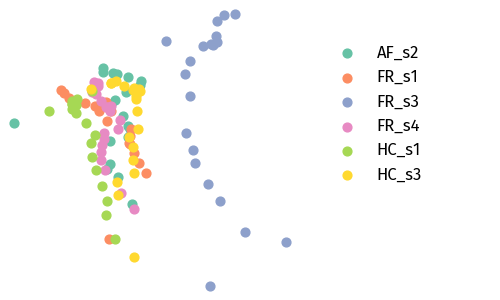

In [21]:
fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0, right=0.6, bottom=0, top=1)
cmap = plt.colormaps['Set2']
for s, c in zip(pca_df["sample"].unique(), cmap.colors):
    tmp = pca_df[pca_df["sample"] == s]

    ax.scatter(
        tmp["PC1_per_cell"],
        tmp["PC2_per_cell"],
        label=s,
        s=40, 
        c=c
    )
ax.axis("off")
ax.legend(frameon=False, bbox_to_anchor=[1.05,0.9], fontsize=12, loc="upper left")

fig.savefig(f"{REV_PATH}per-cell_neighborhood_expression_PCA_sample.png", dpi=500, format="png", bbox_inches=None)


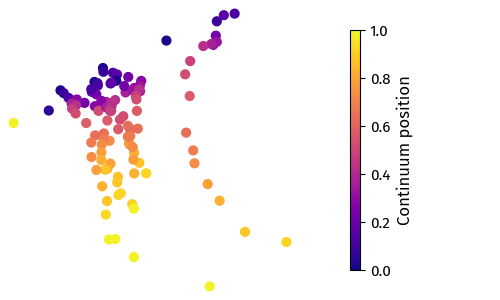

In [22]:
fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0, right=0.6, bottom=0, top=1)
cmap = plt.colormaps['Set2']

sc = ax.scatter(
    pca_df["PC1_per_cell"],
    pca_df["PC2_per_cell"],
    c=pca_df["mean_continuum_position"],
    s=40,
    vmin=0,
    vmax=1,
    cmap="plasma"
)

ax.axis("off")

ax_cbar = fig.add_axes([0.7, 0.1, 0.02, 0.8])
plt.colorbar(sc, cax=ax_cbar)
ax_cbar.tick_params("y", labelsize=11)
ax_cbar.set_ylabel("Continuum position", fontsize=12)

fig.savefig(f"{REV_PATH}per-cell_neighborhood_expression_PCA_Cposition.png", dpi=500, format="png", bbox_inches=None)


## Composition-adjusted residual

In [23]:
gene_names = adata.var_names[keep_genes]

rho_list = []

for j in range(X_pc.shape[1]):
    rho, p = spearmanr(
        X_pc[:, j],
        pca_df["mean_continuum_position"]
    )

    rho_list.append((gene_names[j], rho, p))

gene_corr_df = pd.DataFrame(
    rho_list,
    columns=["gene", "rho", "p"]
)

gene_corr_df["abs_rho"] = gene_corr_df["rho"].abs()


In [24]:
def build_composition_adjusted_residual(
    adata,
    anchor_obs,
    sample,
    X,
    neigh_result
):
    sample_mask = adata.obs["sample"].astype(str).values == sample
    sample_idx = np.where(sample_mask)[0]

    sample_cells = adata.obs_names[sample_idx]
    X_sample = X[sample_idx]

    sample_subtypes = (
        adata.obs.loc[sample_cells, "subtype"]
        .astype(str)
    )

    # subtype-specific mean expression within this sample
    subtypes = sorted(sample_subtypes.unique())

    mu_list = []

    for st in subtypes:
        mask = sample_subtypes.values == st

        mu = np.asarray(
            X_sample[mask].mean(axis=0)
        ).ravel()

        mu_list.append(mu)

    mu_sample = np.vstack(mu_list)

    # actual neighborhood subtype counts
    A = neigh_result["A"]

    # cell × subtype one-hot matrix
    subtype_cat = pd.Categorical(
        sample_subtypes,
        categories=subtypes
    )

    rows = np.arange(len(sample_cells))
    cols = subtype_cat.codes
    valid = cols >= 0

    C = sparse.csr_matrix(
        (
            np.ones(valid.sum(), dtype=np.float32),
            (rows[valid], cols[valid])
        ),
        shape=(len(sample_cells), len(subtypes))
    )

    # anchor × subtype counts
    C_anchor = A @ C

    n_cells = np.asarray(
        C_anchor.sum(axis=1)
    ).ravel()

    # composition-only expression
    comp_expr = C_anchor @ mu_sample

    comp_expr_per_cell = (
        np.asarray(comp_expr)
        / np.maximum(n_cells[:, None], 1)
    )

    # observed per-cell expression
    observed = neigh_result["neigh_expr_per_cell"]

    if sparse.issparse(observed):
        observed = observed.toarray()
    else:
        observed = np.asarray(observed)

    # log-scale residual
    residual_log = (
        np.log1p(observed)
        - np.log1p(comp_expr_per_cell)
    )

    return {
        "subtypes": subtypes,
        "mu_sample": mu_sample,
        "comp_expr_per_cell": comp_expr_per_cell,
        "residual_log": residual_log
    }

In [25]:
residual_results = {}

for s in samples:

    print("Processing residual:", s)

    residual_results[s] = build_composition_adjusted_residual(
        adata=adata,
        anchor_obs=anchor_obs,
        sample=s,
        X=X,
        neigh_result=neigh_results[s]
    )


Processing residual: AF_s2
Processing residual: FR_s1
Processing residual: FR_s3
Processing residual: FR_s4
Processing residual: HC_s1
Processing residual: HC_s3


In [26]:
all_residual_bin = []
all_residual_info = []

for s in samples:

    residual = residual_results[s]["residual_log"]
    meta = neigh_results[s]["meta"]

    bin_ids = meta["continuum_bin"].to_numpy()

    for b in sorted(meta["continuum_bin"].dropna().unique()):

        mask = bin_ids == b

        all_residual_bin.append(
            residual[mask].mean(axis=0)
        )

        all_residual_info.append({
            "sample": s,
            "continuum_bin": int(b),
            "n_anchors": int(mask.sum()),
            "mean_continuum_position":
                meta.loc[mask, "continuum_position"].mean()
        })

all_residual_bin = np.vstack(all_residual_bin)
all_residual_info = pd.DataFrame(all_residual_info)

print(all_residual_bin.shape)
print(all_residual_info.shape)

(118, 5001)
(118, 4)


In [27]:
X_res_all = all_residual_bin[:, keep_genes]

pca_res_all = PCA(n_components=10)
pcs_res_all = pca_res_all.fit_transform(X_res_all)

In [28]:
res_pca_df = all_residual_info.copy()

for i in range(n_pca):
    res_pca_df[f"PC{i+1}_raw"] = pcs_res_all[:, i]

In [29]:
bar_car = pd.DataFrame(0.0, 
                         index=[f"PC{n+1}" for n in range(n_pca)], 
                         columns=["rho", "p", "variance"]
                        )

cols_car = [f"PC{n+1}_raw" for n in range(n_pca)]
vrs =  pca_res_all.explained_variance_ratio_[:n_pca]
for n, (col, vr) in enumerate(zip(cols_car, vrs)):
    rho, p = spearmanr(res_pca_df[col], res_pca_df["mean_continuum_position"])
    bar_car.loc[f"PC{n+1}", "rho"] = rho
    bar_car.loc[f"PC{n+1}", "p"] = p
    bar_car.loc[f"PC{n+1}", "variance"] = vr

bar_car["abs_rho"] = bar_car["rho"].abs()



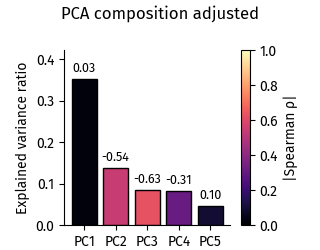

In [30]:
fig, ax = plt.subplots(figsize=(3.2, 2.5))
fig.subplots_adjust(left=0.2, right=0.85, bottom=0.1, top=0.8)

# Color: |Spearman rho|
cmap = plt.colormaps["magma"]
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

bars = ax.bar(x=bar_car.index, height=bar_car["variance"], color=cmap(norm(bar_car["abs_rho"])), ec="black")

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("|Spearman ρ|")

# Spearman rho labels (signed)
for bar, rho in zip(bars, bar_car["rho"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rho:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylabel("Explained variance ratio")
ax.set_ylim(0, bar_car["variance"].max() * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.suptitle("PCA composition adjusted")
fig.savefig(f"{REV_PATH}barplot_PCA_composition_adjusted_residual.png", dpi=500, format="png", bbox_inches=None)

/tmp/ipykernel_3693/2275461773.py:9: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


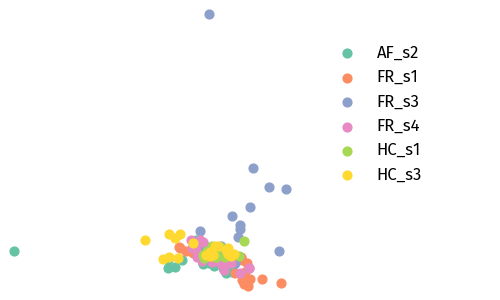

In [31]:
fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0, right=0.6, bottom=0, top=1)
cmap = plt.colormaps['Set2']

for s, c in zip(res_pca_df["sample"].unique(), cmap.colors):

    tmp = res_pca_df[res_pca_df["sample"] == s]

    ax.scatter(
        tmp["PC1_raw"],
        tmp["PC2_raw"],
        label=s,
        s=40,
        c=c
    )

ax.axis("off")
ax.legend(frameon=False, bbox_to_anchor=[1.05,0.9], fontsize=12, loc="upper left")


fig.savefig(f"{REV_PATH}composition-adjusted_residual_PCA_sample.png", dpi=500, format="png", bbox_inches=None)


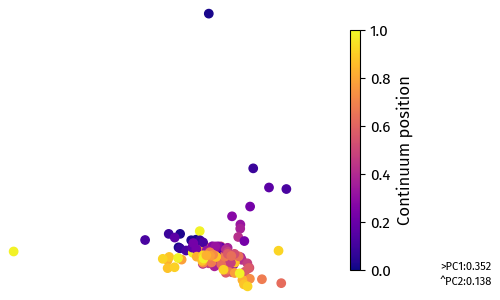

In [32]:
fig, ax = plt.subplots(figsize=(5, 3))
fig.subplots_adjust(left=0, right=0.6, bottom=0, top=1)
cmap = plt.colormaps['Set2']

sc = ax.scatter(
    res_pca_df["PC1_raw"],
    res_pca_df["PC2_raw"],
    c=res_pca_df["mean_continuum_position"],
    vmin=0,
    vmax=1,
    cmap="plasma"
)

ax.axis("off")
ax_cbar = fig.add_axes([0.7, 0.1, 0.02, 0.8])
plt.colorbar(sc, cax=ax_cbar)
ax_cbar.tick_params("y", labelsize=11)
ax_cbar.set_ylabel("Continuum position", fontsize=12)

pc_r = pca_res_all.explained_variance_ratio_[:2]
fig.text(s=f">PC1:{pc_r[0]:.3f}", x=0.88, y=0.1, fontsize=8)
fig.text(s=f"^PC2:{pc_r[1]:.3f}", x=0.88, y=0.05, fontsize=8)

fig.savefig(f"{REV_PATH}composition-adjusted_residual_PCA_Cposition.png", dpi=500, format="png", bbox_inches=None)


## Sample-centered composition-adjusted residual expression

In [33]:
X_res_centered = all_residual_bin.copy()

for s in all_residual_info["sample"].unique():
    mask = (all_residual_info["sample"].values == s)
    sample_mean = X_res_centered[mask].mean(axis=0,keepdims=True)
    X_res_centered[mask] -= sample_mean

In [34]:
X_center = X_res_centered[:, keep_genes]

pca_center = PCA(n_components=10)
pcs_center = pca_center.fit_transform(X_center)

print("Centered explained variance:",pca_center.explained_variance_ratio_[:5])

Centered explained variance: [0.35377333 0.13511977 0.0941294  0.0620438  0.04465518]


In [35]:
for i in range(5):
    res_pca_df[f"PC{i+1}_centered"] = pcs_center[:, i]

In [36]:
for i in range(5):

    rho, p = spearmanr(
        res_pca_df[f"PC{i+1}_centered"],
        res_pca_df["mean_continuum_position"]
    )

    print(
        f"Centered residual PC{i+1}:",
        "rho =", round(rho, 3),
        "p =", p
    )

Centered residual PC1: rho = 0.007 p = 0.9398977281514032
Centered residual PC2: rho = -0.818 p = 1.290502290957761e-29
Centered residual PC3: rho = -0.787 p = 4.097033071149458e-26
Centered residual PC4: rho = 0.589 p = 2.234975503806651e-12
Centered residual PC5: rho = -0.081 p = 0.38462025670722666


In [37]:
bar_sc = pd.DataFrame(0.0, 
                         index=[f"PC{n+1}" for n in range(n_pca)], 
                         columns=["rho", "p", "variance"]
                        )

cols_sc = [f"PC{n+1}_centered" for n in range(n_pca)]
vrs =  pca_center.explained_variance_ratio_[:n_pca]
for n, (col, vr) in enumerate(zip(cols_sc, vrs)):
    rho, p = spearmanr(res_pca_df[col], res_pca_df["mean_continuum_position"])
    bar_sc.loc[f"PC{n+1}", "rho"] = rho
    bar_sc.loc[f"PC{n+1}", "p"] = p
    bar_sc.loc[f"PC{n+1}", "variance"] = vr

bar_sc["abs_rho"] = bar_sc["rho"].abs()



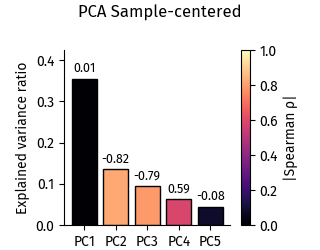

In [38]:
fig, ax = plt.subplots(figsize=(3.2, 2.5))
fig.subplots_adjust(left=0.2, right=0.85, bottom=0.1, top=0.8)

# Color: |Spearman rho|
cmap = plt.colormaps["magma"]
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)

bars = ax.bar(x=bar_sc.index, height=bar_sc["variance"], color=cmap(norm(bar_sc["abs_rho"])), ec="black")

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("|Spearman ρ|")

# Spearman rho labels (signed)
for bar, rho in zip(bars, bar_sc["rho"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rho:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylabel("Explained variance ratio")
ax.set_ylim(0, bar_sc["variance"].max() * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.suptitle("PCA Sample-centered")

fig.savefig(f"{REV_PATH}barplot_PCA_sample_centered.png", dpi=500, format="png", bbox_inches="tight")

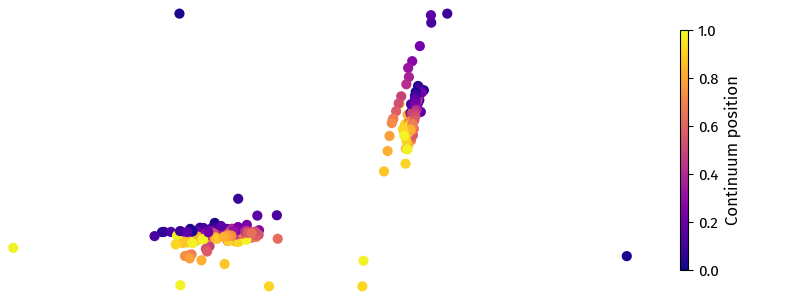

In [39]:
fig, (ax12, ax23) = plt.subplots(1,2,figsize=(8, 3))
fig.subplots_adjust(left=0, right=0.8, bottom=0, top=1)
cmap = plt.colormaps['Set2']

sc = ax12.scatter(
    res_pca_df["PC1_centered"],
    res_pca_df["PC2_centered"],
    c=res_pca_df["mean_continuum_position"],
    s=40,
    vmin=0,
    vmax=1,
    cmap="plasma"
)


sc = ax23.scatter(
    res_pca_df["PC2_centered"],
    res_pca_df["PC3_centered"],
    c=res_pca_df["mean_continuum_position"],
    s=40,
    vmin=0,
    vmax=1,
    cmap="plasma"
)

ax12.axis("off")
ax23.axis("off")

ax_cbar = fig.add_axes([0.85, 0.1, 0.01, 0.8])
plt.colorbar(sc, cax=ax_cbar)
ax_cbar.tick_params("y", labelsize=11)
ax_cbar.set_ylabel("Continuum position", fontsize=12)


fig.savefig(f"{REV_PATH}Sample_centered_composition-adjusted_residual_PCA_Cposition.png", dpi=500, format="png", bbox_inches=None)



/tmp/ipykernel_3693/3260639185.py:9: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax12.scatter(
/tmp/ipykernel_3693/3260639185.py:21: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax23.scatter(


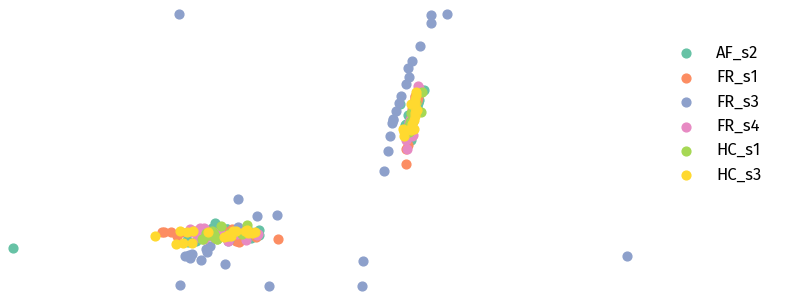

In [40]:
fig, (ax12, ax23) = plt.subplots(1,2,figsize=(8, 3))
fig.subplots_adjust(left=0, right=0.8, bottom=0, top=1)
cmap = plt.colormaps['Set2']

for s, c in zip(res_pca_df["sample"].unique(), cmap.colors):

    tmp = res_pca_df[res_pca_df["sample"] == s]

    ax12.scatter(
        tmp["PC1_centered"],
        tmp["PC2_centered"],
        label=s,
        s=40,
        c=c
    )

for s, c in zip(res_pca_df["sample"].unique(), cmap.colors):

    tmp = res_pca_df[res_pca_df["sample"] == s]

    ax23.scatter(
        tmp["PC2_centered"],
        tmp["PC3_centered"],
        label=s,
        s=40,
        c=c
    )

ax12.axis("off")
ax23.axis("off")
ax23.legend(frameon=False, bbox_to_anchor=[1.05,0.9], fontsize=12, loc="upper left")

fig.savefig(f"{REV_PATH}Sample-centered_composition-adjusted_residual_PCA_sample.png", dpi=500, format="png", bbox_inches=None)


In [41]:
sample_pc_corr = []

for s in res_pca_df["sample"].unique():

    tmp = res_pca_df[
        res_pca_df["sample"] == s
    ].copy()

    for i in range(n_pca):

        rho, p = spearmanr(
            tmp[f"PC{i+1}_centered"],
            tmp["mean_continuum_position"]
        )

        sample_pc_corr.append({
            "sample": s,
            "PC": f"PC{i+1}",
            "n_bins": len(tmp),
            "rho": rho,
            "p": p
        })

sample_pc_corr = pd.DataFrame(sample_pc_corr)

In [43]:
sample_pc_corr.pivot(index="sample",columns="PC",values="rho")

PC,PC1,PC2,PC3,PC4,PC5
sample,,,,,
AF_s2,-0.386466,-0.977444,-0.673684,0.342857,-0.508271
FR_s1,0.619549,-0.708271,-0.878195,0.702256,0.448120
FR_s3,-0.390977,-0.995489,-0.736842,0.252632,-0.442105
FR_s4,0.443609,-0.966917,-0.887218,0.708271,-0.054135
HC_s1,-0.162023,-0.787410,-0.828689,0.424149,-0.465428
HC_s3,0.057143,-0.735338,-0.989474,0.887218,-0.198496


## Changes in representative gene expression

In [41]:
gene_rows = []

for j, gene in enumerate(adata.var_names):

    rho, p = spearmanr(
        X_res_centered[:, j],
        all_residual_info["mean_continuum_position"]
    )

    gene_rows.append({
        "gene": gene,
        "rho": rho,
        "p": p
    })

tx_gene_corr = pd.DataFrame(gene_rows)

tx_gene_corr["abs_rho"] = tx_gene_corr["rho"].abs()

tx_gene_corr = tx_gene_corr.sort_values(
    "abs_rho",
    ascending=False
)

In [42]:
top_genes = (
    tx_gene_corr
    .head(100)["gene"]
    .tolist()
)

top_idx = [
    adata.var_names.get_loc(g)
    for g in top_genes
]

sample_gene_corr = []

for s in all_residual_info["sample"].unique():

    mask = (
        all_residual_info["sample"].values == s
    )

    pos = all_residual_info.loc[
        mask,
        "mean_continuum_position"
    ].to_numpy()

    for gene, j in zip(top_genes, top_idx):

        rho, p = spearmanr(
            X_res_centered[mask, j],
            pos
        )

        sample_gene_corr.append({
            "sample": s,
            "gene": gene,
            "rho": rho,
            "p": p
        })

sample_gene_corr = pd.DataFrame(sample_gene_corr)

In [43]:
gene_consistency = (
    sample_gene_corr
    .groupby("gene")
    .agg(
        median_rho=("rho", "median"),
        min_rho=("rho", "min"),
        max_rho=("rho", "max"),
        n_positive=("rho", lambda x: (x > 0).sum()),
        n_negative=("rho", lambda x: (x < 0).sum())
    )
    .reset_index()
)

gene_consistency = gene_consistency.merge(
    tx_gene_corr[
        ["gene", "rho", "abs_rho"]
    ].rename(
        columns={"rho": "global_rho"}
    ),
    on="gene"
)

In [44]:
gene_consistency = (
    sample_gene_corr
    .groupby("gene")
    .agg(
        median_rho=("rho", "median"),
        min_rho=("rho", "min"),
        max_rho=("rho", "max"),
        n_positive=("rho", lambda x: (x > 0).sum()),
        n_negative=("rho", lambda x: (x < 0).sum())
    )
    .reset_index()
)

gene_consistency = gene_consistency.merge(
    tx_gene_corr[
        ["gene", "rho", "abs_rho"]
    ].rename(
        columns={"rho": "global_rho"}
    ),
    on="gene"
)

In [45]:
candidate_genes = gene_consistency[
    (
        (gene_consistency["n_positive"] == 6) |
        (gene_consistency["n_negative"] == 6)
    )
].copy()

candidate_genes = candidate_genes.sort_values(
    "abs_rho",
    ascending=False
)

candidate = gene_consistency[
    (gene_consistency["n_positive"] == 6) |
    (gene_consistency["n_negative"] == 6)
].copy()

candidate = candidate.sort_values(
    "abs_rho",
    ascending=False
)

In [46]:
target_genes = candidate_genes.head(5)["gene"].tolist()

In [47]:
plot_list = []

for gene in target_genes:

    j = adata.var_names.get_loc(gene)

    temp = all_residual_info[
        ["sample", "mean_continuum_position"]
    ].copy()

    temp["gene"] = gene
    temp["residual"] = X_res_centered[:, j]

    plot_list.append(temp)

plot_df = pd.concat(
    plot_list,
    ignore_index=True
)


In [48]:
plot_df["continuum_plot_bin"] = pd.cut(
    plot_df["mean_continuum_position"],
    bins=np.linspace(0, 1, 11),
    labels=False,
    include_lowest=True
)

summary_df = (
    plot_df
    .groupby(
        ["gene", "continuum_plot_bin"],
        observed=True
    )
    .agg(
        continuum_position=(
            "mean_continuum_position",
            "mean"
        ),
        mean_residual=(
            "residual",
            "mean"
        ),
        sem_residual=(
            "residual",
            lambda x: x.std(ddof=1) / np.sqrt(len(x))
        )
    )
    .reset_index()
)

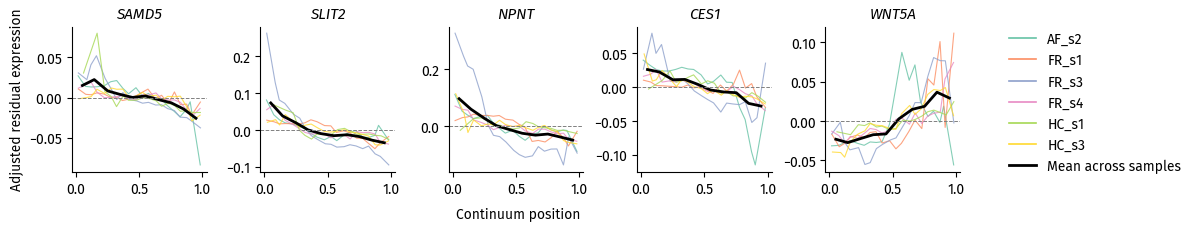

In [49]:
fig, axes = plt.subplots(
    1, 5,
    figsize=(12, 2.3),
    sharex=True
)
fig.subplots_adjust(left=0.06, right=0.8, bottom=0.25, top=0.88, wspace=0.4)
samples = all_residual_info["sample"].unique()
cmap = plt.colormaps['Set2']

for ax, gene in zip(axes, target_genes):

    df_gene = plot_df[
        plot_df["gene"] == gene
    ]

    # sample-specific trajectories
    for c, sample in enumerate(samples):

        df_s = (
            df_gene[
                df_gene["sample"] == sample
            ]
            .sort_values("mean_continuum_position")
        )

        ax.plot(
            df_s["mean_continuum_position"],
            df_s["residual"],
            linewidth=0.8,
            alpha=0.8,
            c=cmap(c)
        )

    # overall trend
    df_sum = (
        summary_df[
            summary_df["gene"] == gene
        ]
        .sort_values("continuum_position")
    )

    ax.plot(
        df_sum["continuum_position"],
        df_sum["mean_residual"],
        color="black",
        linewidth=2
    )

    ax.axhline(
        0,
        linewidth=0.7,
        linestyle="--",
        color="gray"
    )

    ax.set_title(
        gene,
        fontsize=11,
        fontstyle="italic"
    )

    ax.set_xlabel("")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
fig.text(s="Continuum position", x=0.38, y=0.05)

axes[0].set_ylabel(
    "Adjusted residual expression"
)


legend_handles = [
    Line2D(
        [0], [0],
        color=cmap(c),
        lw=1.2,
        label=sample
    )
    for c, sample in enumerate(samples)
]

legend_handles.append(
    Line2D(
        [0], [0],
        color="black",
        lw=2,
        label="Mean across samples"
    )
)

fig.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(0.83, 0.55),
    frameon=False,
    fontsize=10
)

fig.savefig(f"{REV_PATH}gene_changes_top5.png", dpi=500, format="png", bbox_inches=None)


In [50]:

# 1. Sample-specific trajectories
df_samples = (
    plot_df.loc[
        plot_df["gene"].isin(target_genes),
        [
            "gene",
            "sample",
            "mean_continuum_position",
            "residual"
        ]
    ]
    .copy()
    .rename(columns={
        "gene": "Gene",
        "sample": "Sample",
        "mean_continuum_position": "Continuum_position",
        "residual": "Adjusted_residual_expression"
    })
    .sort_values(["Gene", "Sample", "Continuum_position"])
    .reset_index(drop=True)
)

# 2. Mean trajectory across samples
df_mean = (
    summary_df.loc[
        summary_df["gene"].isin(target_genes),
        [
            "gene",
            "continuum_position",
            "mean_residual"
        ]
    ]
    .copy()
    .rename(columns={
        "gene": "Gene",
        "continuum_position": "Continuum_position",
        "mean_residual": "Mean_adjusted_residual_expression"
    })
    .sort_values(["Gene", "Continuum_position"])
    .reset_index(drop=True)
)


In [56]:
# Sample-specific trajectories
df_samples = (
    plot_df.loc[
        plot_df["gene"].isin(target_genes),
        ["gene", "sample", "mean_continuum_position", "residual"]
    ]
    .rename(columns={
        "gene": "Gene",
        "sample": "Sample",
        "mean_continuum_position": "Continuum_position",
        "residual": "Adjusted_residual_expression"
    })
    .copy()
)

# Mean trajectory across samples
df_mean = (
    summary_df.loc[
        summary_df["gene"].isin(target_genes),
        ["gene", "continuum_position", "mean_residual"]
    ]
    .rename(columns={
        "gene": "Gene",
        "continuum_position": "Continuum_position",
        "mean_residual": "Adjusted_residual_expression"
    })
    .copy()
)

df_mean["Sample"] = "Mean across samples"

# 統合
df_source = pd.concat(
    [df_samples, df_mean],
    ignore_index=True
)

df_source = (
    df_source[
        ["Gene", "Sample", "Continuum_position", "Adjusted_residual_expression"]
    ]
    .sort_values(["Gene", "Sample", "Continuum_position"])
    .reset_index(drop=True)
)

df_source.to_csv(f"{REV_PATH}gene_changes_top5_source_data.csv", index=True)

In [58]:
gene_idx = [adata.var_names.get_loc(g) for g in target_genes]

result_list = []

for sample in anchor_obs["sample"].unique():

    print(sample)

    # -----------------------------
    # cells in this sample
    # -----------------------------
    cell_mask = (
        adata.obs["sample"].values == sample
    )

    ad_s = adata[cell_mask]

    # -----------------------------
    # epithelial anchors
    # -----------------------------
    anchor_s = anchor_obs.loc[
        anchor_obs["sample"] == sample
    ].copy()

    # anchor_obs.index が adata.obs_names と一致している前提
    anchor_pos = adata[
        anchor_s.index
    ].obsm["spatial"]

    cell_pos = ad_s.obsm["spatial"]

    # -----------------------------
    # neighborhood adjacency
    # anchor × all cells
    # -----------------------------
    tree = cKDTree(cell_pos)

    neighbors = tree.query_ball_point(
        anchor_pos,
        r=radius
    )

    rows = []
    cols = []

    for i, inds in enumerate(neighbors):
        rows.extend([i] * len(inds))
        cols.extend(inds)

    A = sparse.csr_matrix(
        (
            np.ones(len(rows)),
            (rows, cols)
        ),
        shape=(
            len(anchor_s),
            ad_s.n_obs
        )
    )

    # -----------------------------
    # selected-gene expression
    # cells × 5 genes
    # -----------------------------
    Xg = ad_s[:, gene_idx].X

    if sparse.issparse(Xg):
        Xg = Xg.tocsr()
    else:
        Xg = sparse.csr_matrix(Xg)

    subtypes = ad_s.obs["subtype"].astype(str)

    # -----------------------------
    # each subtype
    # -----------------------------
    for subtype in subtypes.unique():

        subtype_mask = (
            subtypes.values == subtype
        )

        n_subtype_cells = subtype_mask.sum()

        if n_subtype_cells == 0:
            continue

        # --------------------------------
        # subtype cell count per neighborhood
        # N_ik
        # --------------------------------
        indicator = subtype_mask.astype(float)

        N_ik = np.asarray(
            A @ indicator
        ).ravel()

        # subtypeが存在しないneighborhoodは後で除外
        valid_anchor = N_ik > 0

        if valid_anchor.sum() == 0:
            continue

        # --------------------------------
        # actual transcript count
        # Y_ikg
        # --------------------------------
        X_sub = Xg.multiply(
            subtype_mask[:, None]
        )

        Y_ikg = A @ X_sub

        if sparse.issparse(Y_ikg):
            Y_ikg = Y_ikg.toarray()

        # --------------------------------
        # sample × subtype mean expression
        # mu_skg
        # --------------------------------
        mu = np.asarray(
            Xg[subtype_mask].mean(axis=0)
        ).ravel()

        # --------------------------------
        # expected expression
        # N_ik * mu_skg
        # --------------------------------
        expected = (
            N_ik[:, None]
            * mu[None, :]
        )

        # --------------------------------
        # subtype-specific residual per cell
        # --------------------------------

        residual = np.full(
            Y_ikg.shape,
            np.nan,
            dtype=float
        )
        
        residual[valid_anchor] = (
            Y_ikg[valid_anchor] / N_ik[valid_anchor, None]
            - mu[None, :]
        )

        # --------------------------------
        # long-format dataframe
        # --------------------------------
        for j, gene in enumerate(target_genes):

            temp = pd.DataFrame({
                "sample": sample,
                "anchor_id": anchor_s.index,
                "continuum_position":
                    anchor_s["continuum_position"].values,
                "continuum_bin":
                    anchor_s["continuum_bin"].values,
                "subtype": subtype,
                "gene": gene,
                "n_subtype":
                    N_ik,
                "actual":
                    Y_ikg[:, j],
                "expected":
                    expected[:, j],
                "residual":
                    residual[:, j]
            })

            # subtypeが少なくとも1 cell存在する
            # neighborhoodだけ残す
            temp = temp.loc[
                temp["n_subtype"] > 0
            ]

            result_list.append(temp)

AF_s2
FR_s1
FR_s3
FR_s4
HC_s1
HC_s3


In [59]:
subtype_residual_df = pd.concat(
    result_list,
    ignore_index=True
)


In [60]:
subtype_bin_df = (
    subtype_residual_df
    .groupby([
        "sample",
        "subtype",
        "gene",
        "continuum_bin"
    ])
    .agg(
        residual=("residual", "mean"),
        mean_continuum_position=(
            "continuum_position",
            "mean"
        ),
        n_anchors=("anchor_id", "nunique"),
        mean_n_subtype=("n_subtype", "mean")
    )
    .reset_index()
)

In [61]:
corr_rows = []

for gene in target_genes:

    df_gene = subtype_bin_df[
        subtype_bin_df["gene"] == gene
    ]

    for subtype in df_gene["subtype"].unique():

        df_sub = df_gene[
            df_gene["subtype"] == subtype
        ]

        for sample in df_sub["sample"].unique():

            df_ss = df_sub[
                df_sub["sample"] == sample
            ].copy()

            # continuum binが少なすぎるsampleは除外
            if len(df_ss) < 3:
                continue

            rho, p = spearmanr(
                df_ss["mean_continuum_position"],
                df_ss["residual"]
            )

            corr_rows.append({
                "gene": gene,
                "subtype": subtype,
                "sample": sample,
                "rho": rho,
                "p": p,
                "n_bins": len(df_ss)
            })

subtype_sample_corr = pd.DataFrame(
    corr_rows
)

/tmp/ipykernel_3693/1844629850.py:25: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(


In [62]:
subtype_corr_summary = (
    subtype_sample_corr
    .groupby([
        "gene",
        "subtype"
    ])
    .agg(
        median_rho=("rho", "median"),
        min_rho=("rho", "min"),
        max_rho=("rho", "max"),
        n_samples=("rho", "count"),
        n_positive=(
            "rho",
            lambda x: (x > 0).sum()
        ),
        n_negative=(
            "rho",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

In [63]:
magnitude_df = (
    subtype_bin_df
    .groupby([
        "gene",
        "subtype"
    ])
    .agg(
        mean_abs_residual=(
            "residual",
            lambda x: np.mean(np.abs(x))
        ),
        mean_n_subtype=(
            "mean_n_subtype",
            "mean"
        )
    )
    .reset_index()
)

subtype_corr_summary = (
    subtype_corr_summary
    .merge(
        magnitude_df,
        on=["gene", "subtype"],
        how="left"
    )
)

In [64]:
heat_df = subtype_corr_summary[
    subtype_corr_summary["gene"].isin(target_genes)
].copy()

rho_mat = heat_df.pivot(
    index="subtype",
    columns="gene",
    values="median_rho"
)

# gene orderを固定
rho_mat = rho_mat.reindex(columns=target_genes)

In [65]:
heat_df["consistent_6of6"] = (
    (heat_df["n_samples"] == 6) &
    (
        (heat_df["n_positive"] == 6) |
        (heat_df["n_negative"] == 6)
    )
)

consistency_mat = heat_df.pivot(
    index="subtype",
    columns="gene",
    values="consistent_6of6"
)

consistency_mat = consistency_mat.reindex(
    index=rho_mat.index,
    columns=target_genes
)

In [66]:
# 6/6 samples
row_keep = consistency_mat.fillna(False).any(axis=1)

rho_plot = rho_mat.loc[row_keep].copy()
consistency_plot = consistency_mat.loc[row_keep].copy()

# 2. max |median rho|
order = (
    rho_plot.abs()
    .max(axis=1)
    .sort_values(ascending=False)
    .index
)

subtype_order = [
    x for x in list(SUBTYPE_HATCHES.keys())
    if x in rho_plot.index
]

# 3. reorder
rho_plot = rho_plot.loc[order]
consistency_plot = consistency_plot.loc[order]

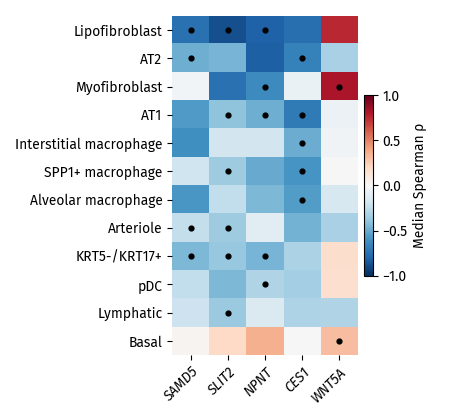

In [67]:
fig, ax = plt.subplots(
    figsize=(4.5, 0.25 * len(rho_plot) + 1.2)
)

im = ax.imshow(
    rho_plot.values,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    np.arange(len(target_genes))
)

ax.set_xticklabels(
    target_genes,
    fontstyle="italic",
    rotation=45,
    rotation_mode="anchor",
    ha="right",
    va="top"
)

ax.set_yticks(
    np.arange(len(rho_plot.index))
)

ax.set_yticklabels(
    rho_plot.index
)

ax.set_xlabel("")
ax.set_ylabel("")

# 6/6 consistent
for i, subtype in enumerate(rho_plot.index):
    for j, gene in enumerate(target_genes):

        val = consistency_plot.loc[
            subtype, gene
        ]

        if pd.notna(val) and val:
            ax.scatter(
                j,
                i,
                s=12,
                color="black"
            )

# colorbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "Median Spearman ρ"
)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.tight_layout()

fig.savefig(f"{REV_PATH}gene_changes_top5_heatmap.png", dpi=500, format="png", bbox_inches=None)


In [68]:
subtypes = rho_plot.index
genes = target_genes

records = []

for subtype in subtypes:
    for gene in genes:

        rho = rho_plot.loc[subtype, gene]
        consistent = consistency_plot.loc[subtype, gene]

        records.append({
            "Cell_subtype": subtype,
            "Gene": gene,
            "Median_Spearman_rho": rho,
            "Consistent_6_of_6_samples": (
                bool(consistent) if pd.notna(consistent) else False
            )
        })

df_source = pd.DataFrame(records)


df_source.to_csv(f"{REV_PATH}gene_changes_top5_heatmap.csv", index=True)

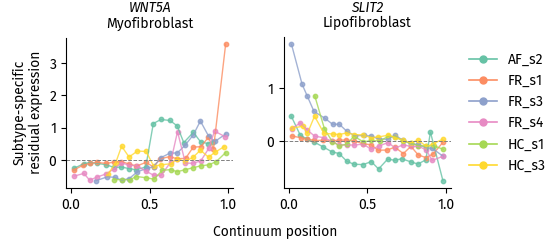

In [70]:
pairs = [("WNT5A", "Myofibroblast"), ("SLIT2", "Lipofibroblast")]

samples = subtype_bin_df["sample"].unique()
cmap = plt.colormaps["Set2"]

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.5), sharex=True)
fig.subplots_adjust(left=0.12, right=0.82, bottom=0.25, top=0.85, wspace=0.3)

for ax, (gene, subtype) in zip(axes, pairs):

    df_plot = subtype_bin_df[
        (subtype_bin_df["gene"] == gene) &
        (subtype_bin_df["subtype"] == subtype)
    ].copy()

    # sample-specific trajectories
    for c, sample in enumerate(samples):

        df_s = (
            df_plot[
                df_plot["sample"] == sample
            ]
            .sort_values("mean_continuum_position")
        )

        if len(df_s) == 0:
            continue

        ax.plot(
            df_s["mean_continuum_position"],
            df_s["residual"],
            linewidth=1.0,
            alpha=0.8,
            color=cmap(c)
        )

        ax.scatter(
            df_s["mean_continuum_position"],
            df_s["residual"],
            s=10,
            alpha=0.8,
            color=cmap(c)
        )

    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.7
    )

    fig.text(
        x=ax.get_position().x0+ax.get_position().width/2,
        y=0.95,
        s=gene,
        fontstyle="italic", 
        ha="center"
    )
    fig.text(
        x=ax.get_position().x0+ax.get_position().width/2,
        y=0.89,
        s=subtype,
        ha="center"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xlabel("")

fig.text(
    0.5,
    0.06,
    "Continuum position",
    ha="center"
)

axes[0].set_ylabel(
    "Subtype-specific\nresidual expression"
)


legend_handles = [
    Line2D(
        [0], [0],
        color=cmap(c),
        lw=1.2,
        label=sample,
        marker="o",
        markersize=5,
    )
    for c, sample in enumerate(samples)
]

fig.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(0.83, 0.55),
    frameon=False,
    fontsize=10
)


fig.savefig(f"{REV_PATH}gene_changes_represantative.png", dpi=500, format="png", bbox_inches=None)


In [71]:
df_source = pd.concat(
    [
        subtype_bin_df.loc[
            (subtype_bin_df["gene"] == gene) &
            (subtype_bin_df["subtype"] == subtype),
            [
                "gene",
                "subtype",
                "sample",
                "mean_continuum_position",
                "residual"
            ]
        ]
        for gene, subtype in pairs
    ],
    ignore_index=True
)

df_source = df_source.rename(columns={
    "gene": "Gene",
    "subtype": "Cell_subtype",
    "sample": "Sample",
    "mean_continuum_position": "Continuum_position",
    "residual": "Subtype_specific_residual_expression"
})

df_source = (
    df_source
    .sort_values(
        ["Gene", "Cell_subtype", "Sample", "Continuum_position"]
    )
    .reset_index(drop=True)
)


df_source.to_csv(f"{REV_PATH}gene_changes_represantative.csv", index=True)